# Calculation of a UV/Vis Spectrum

This tutorial demonstrates the calculation of an electronic absorption (UV/Vis) spectrum using the ORCA python interface (OPI).

We use **benzene** as an example. Its absorption spectrum is a textbook case with three π→π* bands, which in the gas phase have their maxima at 253 nm (¹B₂u), 200 nm (¹B₁u) and 178 nm (¹E₁u) [1]. Only the ¹E₁u band is electric-dipole allowed in the D₆h point group, while the two weaker bands at longer wavelengths gain their intensity through vibronic coupling. This makes benzene a good example of both what a calculation of vertical excitations can show and what it cannot.

In this notebook we will:
1.  Install and import the required Python dependencies
2.  Define a working directory
3.  Set up an input structure for our calculation
4.  Optimize the geometry
5.  Calculate the vertical excitation energies with TD-DFT
6.  Extract the excitation energies and oscillator strengths
7.  Convolute the transitions to a spectrum, plot it and compare it to experiment

## Step 1: Installing 3rd-party Dependencies

In [ ]:
import sys
!{sys.executable} -m pip install --upgrade numpy py3Dmol matplotlib

## Step 2: Import Dependencies

We start by importing the modules needed for:
- Interfacing with ORCA input/output
- Numerical calculations and data handling
- Plotting results

> **Note:** We additionally import modules for visualization/plotting like `py3Dmol`. For this, it might be necessary to install `py3Dmol` into your OPI `venv` (e.g., by activating the `.venv` and using `uv pip install py3Dmol`).

In [1]:
# > Import pathlib for directory handling
from pathlib import Path
import shutil

# > Import numpy for data handling and numerical operations
import numpy as np
# > Import libraries for visualization
import matplotlib.pyplot as plt
import py3Dmol

# > OPI imports for performing ORCA calculations and reading output
from opi.core import Calculator
from opi.input.simple_keywords import (
    Approximation,
    AuxBasisSet,
    BasisSet,
    Dft,
    Task,
)
from opi.input.structures.structure import Structure
from opi.input.blocks.block_tddft import BlockTddft
from opi.output.core import Output
from opi.utils.units import EV_TO_CM, EV_TO_NM

## Step 3: Define Working Directory

All actual calculations will be performed in a subfolder **uvvis_spectrum**.

In [2]:
# > Calculation is performed in `uvvis_spectrum`
working_dir = Path("uvvis_spectrum")
# > The `working_dir` is automatically (re-)created
shutil.rmtree(working_dir, ignore_errors=True)
working_dir.mkdir()

# > Number of CPU cores used for each ORCA run
ncores = 4

## Step 4: Setup an Input Structure

We use **benzene** as our example molecule. The 3D structure in Cartesian coordinates is defined in XYZ format and visualized.

In [3]:
# > Define the molecule's Cartesian coordinates in Angstroem as python string
xyz_data = """\
12

C            1.39200000000000        0.00000000000000        0.00000000000000
C            0.69600000000000        1.20550736206794        0.00000000000000
C           -0.69600000000000        1.20550736206794        0.00000000000000
C           -1.39200000000000        0.00000000000000        0.00000000000000
C           -0.69600000000000       -1.20550736206794        0.00000000000000
C            0.69600000000000       -1.20550736206794        0.00000000000000
H            2.47600000000000        0.00000000000000        0.00000000000000
H            1.23800000000000        2.14427889977027        0.00000000000000
H           -1.23800000000000        2.14427889977027        0.00000000000000
H           -2.47600000000000        0.00000000000000        0.00000000000000
H           -1.23800000000000       -2.14427889977027        0.00000000000000
H            1.23800000000000       -2.14427889977027        0.00000000000000
"""

# > Visualize the molecular structure using py3Dmol
view = py3Dmol.view(width=500, height=500)
view.addModel(xyz_data, "xyz")
view.setStyle({'stick': {'radius': 0.1}, 'sphere': {'scale': 0.2}})
view.setBackgroundColor('white')
view.zoomTo()
view.show()

# > Create the OPI structure directly from the XYZ string
structure = Structure.from_xyz_block(xyz_data, charge=0, multiplicity=1)

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

## Step 5: Geometry Optimization

Vertical excitation energies are sensitive to the ground-state geometry, so we first optimize the structure. The composite method `r2SCAN-3c` is a good and inexpensive choice for this purpose.

We compare to the spectrum of benzene vapor. The intense ¹E₁u band lies in the vacuum UV, below about 200 nm, where common solvents absorb themselves, so it is best characterized in the gas phase. Consequently, no solvation model is used in this tutorial.

We also define a small helper function that checks whether ORCA terminated normally and reads the results afterwards. Since we are only interested in the properties of the calculation, we skip reading the (potentially large) gbw JSON file.

In [4]:
def check_and_parse_output(output: Output) -> None:
    """Check that ORCA terminated normally and read the property JSON file."""
    if not output.terminated_normally():
        raise RuntimeError(
            f"ORCA did not terminate normally, see output file: {output.get_outfile()}"
        )
    # > Only the property JSON file is needed here, hence reading the gbw JSON is skipped
    output.parse(read_gbw_json=False)


# > Create a Calculator object for the geometry optimization
calc_opt = Calculator(basename="opt", working_dir=working_dir)
calc_opt.structure = structure
calc_opt.input.ncores = ncores

# > Add calculation keywords
calc_opt.input.add_simple_keywords(
    Dft.R2SCAN_3C,  # > r2SCAN-3c composite method
    Task.OPT,  # > Optimize the geometry
)

# > Write the ORCA input file and run the calculation
print("Running geometry optimization ...", end="")
calc_opt.write_and_run()
print("   Done")

output_opt = calc_opt.get_output()
check_and_parse_output(output_opt)

# > The optimized structure is the input for the excited-state calculation
opt_structure = output_opt.get_structure()

Running geometry optimization ...

   Done


## Step 6: TD-DFT Calculation of the Excited States

The excitation energies are calculated with TD-DFT. We use the range-separated hybrid `CAM-B3LYP`, which describes the higher-lying excited states of benzene more reliably than a global hybrid. The number of excited states is requested with `nroots` in the `%tddft` block.

By default, ORCA uses the Tamm-Dancoff approximation (TDA), which is cheaper and usually gives very similar excitation energies. Its oscillator strengths, however, do not satisfy the Thomas-Reiche-Kuhn sum rule, and the length and velocity representations do not agree even in a complete basis. Since we convert the oscillator strengths into absolute extinction coefficients below, we switch to full TD-DFT with `tda=False`.

In [5]:
# > Number of excited states to calculate
nroots = 10

# > Create a Calculator object for the TD-DFT calculation
calc_tddft = Calculator(basename="tddft", working_dir=working_dir)
calc_tddft.structure = opt_structure
calc_tddft.input.ncores = ncores

# > Add calculation keywords
calc_tddft.input.add_simple_keywords(
    Dft.CAM_B3LYP,  # > Range-separated hybrid functional
    BasisSet.DEF2_TZVP,  # > def2-TZVP basis set
    AuxBasisSet.DEF2_J,  # > Auxiliary basis set
    Approximation.RIJCOSX,  # > Use RIJ and COSX
)

calc_tddft.input.add_blocks(
    BlockTddft(nroots=nroots, tda=False)  # > Full TD-DFT for the lowest `nroots` states
)

# > Write the ORCA input file and run the calculation
print(f"Running TD-DFT calculation for {nroots} excited states ...", end="")
calc_tddft.write_and_run()
print("   Done")

output = calc_tddft.get_output()
check_and_parse_output(output)

Running TD-DFT calculation for 10 excited states ...

   Done


## Step 7: Vertical Excitation Energies and Oscillator Strengths

`Output.get_absorption_spectrum()` gives direct access to the calculated spectrum. ORCA evaluates the electric-dipole transition moments in both the length and the velocity representation and reports one spectrum for each of them, so we pick the one we are interested in.

The raw data is stored in `excitationenergies`, with one row per transition. Properties such as `energies_ev`, `wavelengths_nm`, `oscillator_strengths` and `transition_moments` return the individual columns, so we do not need to know the layout of the rows.

In [6]:
def get_transitions(
    output: Output, representation: str = "Length"
) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
    """Extract the excitation energies (eV), wavelengths (nm) and oscillator strengths."""
    spectra = output.get_absorption_spectrum()
    if spectra is None:
        raise RuntimeError(
            "No absorption spectrum found. Did the calculation include excited states?"
        )

    for spectrum in spectra:
        if spectrum.representation == representation:
            break
    else:
        raise RuntimeError(f"No absorption spectrum in {representation} representation.")

    # > Each property returns one quantity for all transitions
    energies_ev = np.array(spectrum.energies_ev)
    wavelengths_nm = np.array(spectrum.wavelengths_nm)
    fosc = np.array(spectrum.oscillator_strengths)
    return energies_ev, wavelengths_nm, fosc


energies_ev, wavelengths_nm, fosc = get_transitions(output)

# > Print the transitions as a table
print(f"{'State':>5} {'E / eV':>9} {'lambda / nm':>12} {'fosc':>10}")
for i, (energy, wavelength, f) in enumerate(zip(energies_ev, wavelengths_nm, fosc), start=1):
    print(f"{i:>5} {energy:>9.3f} {wavelength:>12.1f} {f:>10.4f}")

State    E / eV  lambda / nm       fosc
    1     5.510        225.0     0.0000
    2     6.200        200.0     0.0000
    3     7.174        172.8     0.6054
    4     7.176        172.8     0.6053
    5     7.745        160.1     0.0000
    6     7.745        160.1     0.0000
    7     7.931        156.3     0.0000
    8     8.012        154.7     0.0115
    9     8.034        154.3     0.0000
   10     8.034        154.3     0.0000


The calculated transitions can be assigned to the three bands of the measured spectrum:
- States 3 and 4 are degenerate and together form the ¹E₁u state, the only intense transition among the low-lying states. At 172.8 nm (7.17 eV), it lies about 0.2 eV above the measured maximum at 178 nm (6.97 eV). As the two states are degenerate, their sticks coincide in the plot below.
- State 2 at 200.0 nm (6.20 eV) is the ¹B₁u state and agrees well with the measured band at 200 nm. State 1 at 225.0 nm (5.51 eV) is the ¹B₂u state, which TD-DFT places about 0.6 eV above the measured band at 253 nm (4.90 eV), a known weakness of TD-DFT for this state.
- Both the ¹B₂u and the ¹B₁u states have vanishing oscillator strengths, as the transitions into them are symmetry forbidden. The weak bands in the measured spectrum arise from vibronic coupling, which is not part of a calculation of vertical excitations at the equilibrium geometry.
- The higher states are not reliable, as the def2-TZVP basis set lacks the diffuse functions needed to describe Rydberg states, such as the one observed at 179 nm [1].

## Step 8: Broadening and Plotting

A calculation of vertical excitations yields a set of discrete lines, while a measured spectrum shows broad bands. To compare with experiment, each transition is therefore convoluted with a Gaussian of a given full width at half maximum (FWHM).

The oscillator strength $f$ is related to the molar extinction coefficient $\epsilon$ by the sum rule
$$ \int \epsilon(\tilde\nu)\,\mathrm{d}\tilde\nu = 2.3151 \cdot 10^{8}\ f $$
with $\epsilon$ in L mol⁻¹ cm⁻¹ and the wavenumber $\tilde\nu$ in cm⁻¹. Using normalized Gaussians, this lets us report the broadened spectrum directly in the units of a measured spectrum. The measured band maxima of benzene vapor are marked in the plot for comparison.

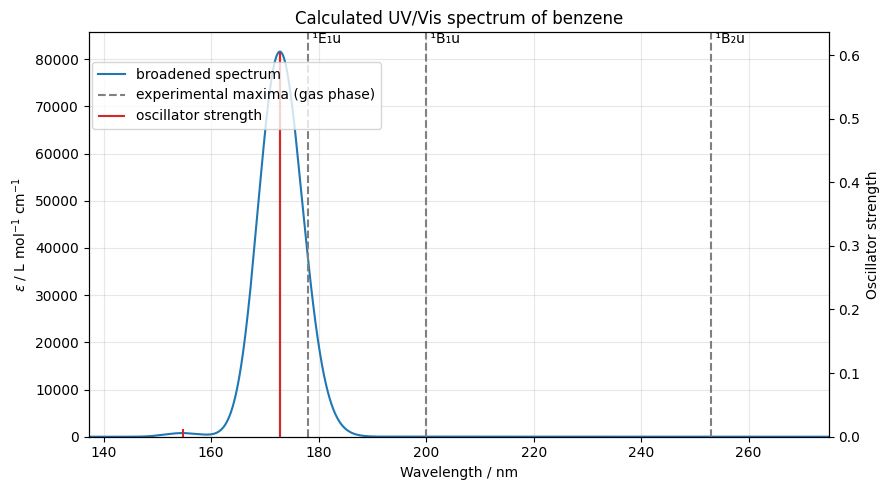

In [7]:
# > Integral of the molar extinction coefficient over wavenumbers per unit
# > oscillator strength, in L mol**-1 cm**-1 cm**-1
EPS_INTEGRAL_PER_FOSC = 2.3151e8
# > Measured band maxima of benzene vapor in nm, see Ref. [1]
LAMBDA_MAX_EXP_NM = {"¹B₂u": 253.0, "¹B₁u": 200.0, "¹E₁u": 178.0}


def broaden_spectrum(
    energies_ev: np.ndarray,
    fosc: np.ndarray,
    *,
    fwhm_ev: float = 0.4,
    margin_ev: float = 1.0,
    npoints: int = 2000,
) -> tuple[np.ndarray, np.ndarray]:
    """Convolute the discrete transitions with normalized Gaussians."""
    sigma = fwhm_ev / (2.0 * np.sqrt(2.0 * np.log(2.0)))
    grid = np.linspace(
        max(energies_ev.min() - margin_ev, 0.1), energies_ev.max() + margin_ev, npoints
    )
    # > Normalized Gaussians on the energy grid (one column per transition)
    deviation = (grid[:, None] - energies_ev[None, :]) / sigma
    gaussians = np.exp(-0.5 * deviation**2) / (sigma * np.sqrt(2.0 * np.pi))
    # > The Gaussians are normalized in eV, hence the conversion to wavenumbers
    epsilon = EPS_INTEGRAL_PER_FOSC / EV_TO_CM * (gaussians @ fosc)
    return grid, epsilon


grid_ev, epsilon = broaden_spectrum(energies_ev, fosc, fwhm_ev=0.4)
grid_nm = EV_TO_NM / grid_ev

fig, ax = plt.subplots(figsize=(9, 5))

# > Broadened spectrum against the wavelength
ax.plot(grid_nm, epsilon, color="tab:blue", label="broadened spectrum")
for i, (state, wavelength) in enumerate(LAMBDA_MAX_EXP_NM.items()):
    ax.axvline(
        wavelength,
        color="gray",
        linestyle="--",
        label="experimental maxima (gas phase)" if i == 0 else None,
    )
    ax.text(wavelength, 1.0, f" {state}", transform=ax.get_xaxis_transform(), va="top")
ax.set_xlabel("Wavelength / nm")
ax.set_ylabel(r"$\epsilon$ / L mol$^{-1}$ cm$^{-1}$")
ax.set_xlim(grid_nm.min(), grid_nm.max())
ax.set_ylim(0.0, 1.05 * epsilon.max())

# > Stick spectrum of the individual transitions on a second axis
ax_sticks = ax.twinx()
ax_sticks.vlines(wavelengths_nm, 0.0, fosc, color="tab:red", label="oscillator strength")
ax_sticks.set_ylabel("Oscillator strength")
ax_sticks.set_ylim(0.0, 1.05 * fosc.max())

ax.set_title("Calculated UV/Vis spectrum of benzene")
ax.grid(True, alpha=0.3)
fig.legend(loc="upper left", bbox_to_anchor=(0.1, 0.88))
fig.tight_layout()
plt.show()

# > Save the broadened spectrum for further processing
np.savetxt(
    working_dir / "uvvis_spectrum.csv",
    np.column_stack((grid_nm, grid_ev, epsilon)),
    delimiter=",",
    header="wavelength/nm,energy/eV,epsilon/(L mol^-1 cm^-1)",
    comments="",
)

## Summary

In this notebook we demonstrated how the ORCA Python interface can be employed to calculate a UV/Vis spectrum: after a geometry optimization, a TD-DFT calculation provides the vertical excitation energies and oscillator strengths, which `Output.get_absorption_spectrum()` makes directly available. Convoluting these transitions with Gaussians yields a spectrum that can be compared to experiment.

A few points to keep in mind when going beyond this example:
- The number of states (`nroots`) determines the spectral range that is covered. States above the highest calculated excitation are missing from the spectrum.
- The broadening width is an empirical parameter. Values between 0.2 and 0.5 eV are common; a vibrationally resolved spectrum requires an excited-state frequency calculation instead.
- Symmetry-forbidden transitions, such as the ¹B₂u and ¹B₁u bands of benzene, have zero oscillator strength in a calculation of vertical excitations. Their intensity is only obtained when vibronic effects are included, e.g., with ORCA's excited-state dynamics (ESD) module.
- Charge-transfer and Rydberg excitations require range-separated functionals such as `CAM-B3LYP` or `ωB97X-D4`, since global hybrids underestimate their energies substantially. Rydberg excitations additionally require diffuse basis functions (e.g., `ma-def2-TZVP`).
- For chiral molecules, ORCA additionally reports the ECD spectrum, which is available in `output.results_properties.geometries[-1].ecd_spectrum`.

## References

[1] E. Pantos, J. Philis, A. Bolovinos, *J. Mol. Spectrosc.* **1978**, *72*, 36–43. [DOI: 10.1016/0022-2852(78)90041-3](https://doi.org/10.1016/0022-2852(78)90041-3)